### Import the libraries

In [5]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

print("Credence Risk project started successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

ModuleNotFoundError: No module named 'seaborn'

### Set the dataset folder

In [ ]:
from pathlib import Path

DATA_PATH = Path(
    r"D:\Credence Risk — Credit Risk Intelligence & Validation Platform\datasets"
)

print("Dataset folder exists:", DATA_PATH.exists())

Dataset folder exists: True


### List all 10 files

In [ ]:
csv_files = sorted(DATA_PATH.glob("*.csv"))

print("Total CSV files:", len(csv_files))
print("\nAvailable datasets:")

for file in csv_files:
    print(file.name)

Total CSV files: 10

Available datasets:
application_test.csv
application_train.csv
bureau.csv
bureau_balance.csv
credit_card_balance.csv
HomeCredit_columns_description.csv
installments_payments.csv
POS_CASH_balance.csv
previous_application.csv
sample_submission.csv


### Step 4 — Create the dataset inventory

In [ ]:

dataset_inventory = []

for file in csv_files:
    encoding_used = "utf-8"

    try:
        columns = pd.read_csv(
            file, nrows=0, encoding="utf-8"
        ).columns.tolist()

    except UnicodeDecodeError:
        encoding_used = "cp1252"
        columns = pd.read_csv(
            file, nrows=0, encoding="cp1252"
        ).columns.tolist()

    with open(file, "rb") as f:
        row_count = sum(1 for _ in f) - 1

    dataset_inventory.append({
        "File Name": file.name,
        "Rows": row_count,
        "Columns": len(columns),
        "Size (MB)": round(
            file.stat().st_size / (1024 ** 2), 2
        ),
        "Encoding": encoding_used
    })

inventory_df = pd.DataFrame(dataset_inventory)

display(
    inventory_df.sort_values(
        "Rows", ascending=False
    ).reset_index(drop=True)
)


,File Name,Rows,Columns,Size (MB),Encoding
0,bureau_balance.csv,27299925,3,358.19,utf-8
1,installments_payments.csv,13605401,8,689.62,utf-8
2,POS_CASH_balance.csv,10001358,8,374.51,utf-8
3,credit_card_balance.csv,3840312,23,404.91,utf-8
4,bureau.csv,1716428,17,162.14,utf-8
5,previous_application.csv,1670214,37,386.21,utf-8
6,application_train.csv,307511,122,158.44,utf-8
7,application_test.csv,48744,121,25.34,utf-8
8,sample_submission.csv,48744,2,0.51,utf-8
9,HomeCredit_columns_description.csv,219,5,0.04,utf-8


### Step 4 — Load the main training dataset
### Load the dataset

In [ ]:
train_path = DATA_PATH / "application_train.csv"

df_train = pd.read_csv(train_path)

print("Dataset loaded successfully")
print("-" * 40)
print("Rows:", df_train.shape[0])
print("Columns:", df_train.shape[1])

Dataset loaded successfully
----------------------------------------
Rows: 307511
Columns: 122


### View the first five rows

In [ ]:
display(df_train.head())

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


### Inspect columns and data types

In [ ]:
print("Column names:")
print(df_train.columns.tolist())

print("\nData types:")
print(df_train.dtypes.value_counts())

print("\nDataset information:")
df_train.info()

Column names:
['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONA

### Step 5 — Analyze the target variable

In [ ]:
print("Target counts:")
print(df_train["TARGET"].value_counts())

print("\nTarget percentages:")
print(
    (df_train["TARGET"].value_counts(normalize=True) * 100)
    .round(2)
)

Target counts:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Target percentages:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


### Step 6: Missing-value analysis

In [ ]:
# Calculate missing values for each column
missing_analysis = pd.DataFrame({
    "Missing_Count": df_train.isnull().sum(),
    "Missing_Percentage": df_train.isnull().mean() * 100
})

# Keep only columns that contain missing values
missing_analysis = missing_analysis[
    missing_analysis["Missing_Count"] > 0
]

# Sort by missing percentage
missing_analysis = missing_analysis.sort_values(
    by="Missing_Percentage",
    ascending=False
)

print("Total columns with missing values:", len(missing_analysis))

display(missing_analysis)

Total columns with missing values: 67


,Missing_Count,Missing_Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_AVG,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
...,...,...
EXT_SOURCE_2,660,0.214626
AMT_GOODS_PRICE,278,0.090403
AMT_ANNUITY,12,0.003902
CNT_FAM_MEMBERS,2,0.000650


### summarize missingness across the dataset

In [ ]:
total_missing = df_train.isnull().sum().sum()
total_cells = df_train.shape[0] * df_train.shape[1]

print("Total missing cells:", total_missing)
print(
    "Overall missing percentage:",
    round((total_missing / total_cells) * 100, 2), "%"
)

Total missing cells: 9152465
Overall missing percentage: 24.4 %


### Step 7 Identify the columns with the most missing valuesm

In [ ]:
# Display the 15 columns with the highest missing percentages
display(missing_analysis.head(15).round(2))

,Missing_Count,Missing_Percentage
COMMONAREA_MEDI,214865,69.87
COMMONAREA_MODE,214865,69.87
COMMONAREA_AVG,214865,69.87
NONLIVINGAPARTMENTS_MODE,213514,69.43
NONLIVINGAPARTMENTS_MEDI,213514,69.43
NONLIVINGAPARTMENTS_AVG,213514,69.43
FONDKAPREMONT_MODE,210295,68.39
LIVINGAPARTMENTS_AVG,210199,68.35
LIVINGAPARTMENTS_MEDI,210199,68.35
LIVINGAPARTMENTS_MODE,210199,68.35


### Step 8 — Visualize missing values

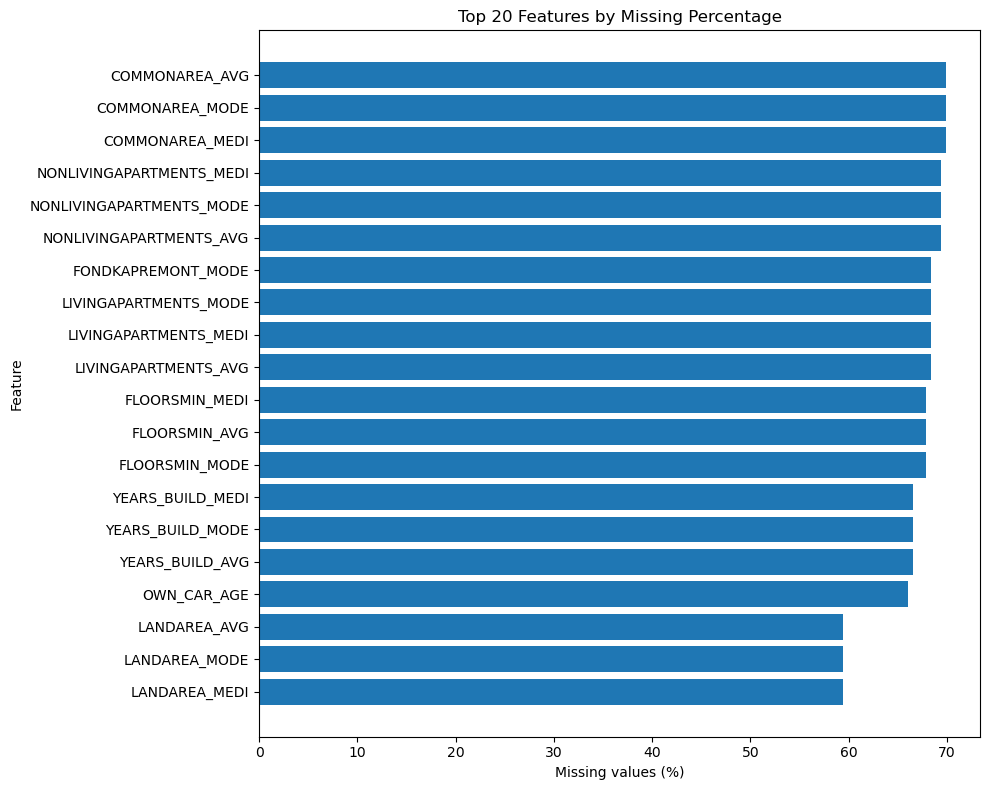

In [ ]:
missing_top = missing_analysis.head(20).sort_values(
    "Missing_Percentage"
)

plt.figure(figsize=(10, 8))

plt.barh(
    missing_top.index,
    missing_top["Missing_Percentage"]
)

plt.xlabel("Missing values (%)")
plt.ylabel("Feature")
plt.title("Top 20 Features by Missing Percentage")

plt.tight_layout()
plt.show()

### Step 9 — Descriptive statistical analysis

### Generate descriptive statistics

In [ ]:
# Descriptive statistics for numerical columns
numeric_summary = df_train.describe().T

display(numeric_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.52,102790.18,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,0.08,0.27,0.0,0.0,0.0,0.0,1.0
CNT_CHILDREN,307511.0,0.42,0.72,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.92,237123.15,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599026.00,402490.78,45000.0,270000.0,513531.0,808650.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.01,0.11,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.03,0.20,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.27,0.92,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.27,0.79,0.0,0.0,0.0,0.0,261.0


### Focus on important financial variables

In [ ]:
financial_columns = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE"
]

display(
    df_train[financial_columns]
    .describe()
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
AMT_INCOME_TOTAL,307511.0,168797.92,237123.15,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599026.00,402490.78,45000.0,270000.0,513531.0,808650.0,4050000.0
AMT_ANNUITY,307499.0,27108.57,14493.74,1615.5,16524.0,24903.0,34596.0,258025.5
AMT_GOODS_PRICE,307233.0,538396.21,369446.46,40500.0,238500.0,450000.0,679500.0,4050000.0


### Compare financial characteristics by target

In [ ]:
target_comparison = (
    df_train.groupby("TARGET")[financial_columns]
    .median()
    .T
)

target_comparison.columns = [
    "TARGET_0_Median",
    "TARGET_1_Median"
]

display(target_comparison.round(2))

,TARGET_0_Median,TARGET_1_Median
AMT_INCOME_TOTAL,148500.0,135000.0
AMT_CREDIT,517788.0,497520.0
AMT_ANNUITY,24876.0,25263.0
AMT_GOODS_PRICE,450000.0,450000.0


### Step 10 — Visualize the financial variables

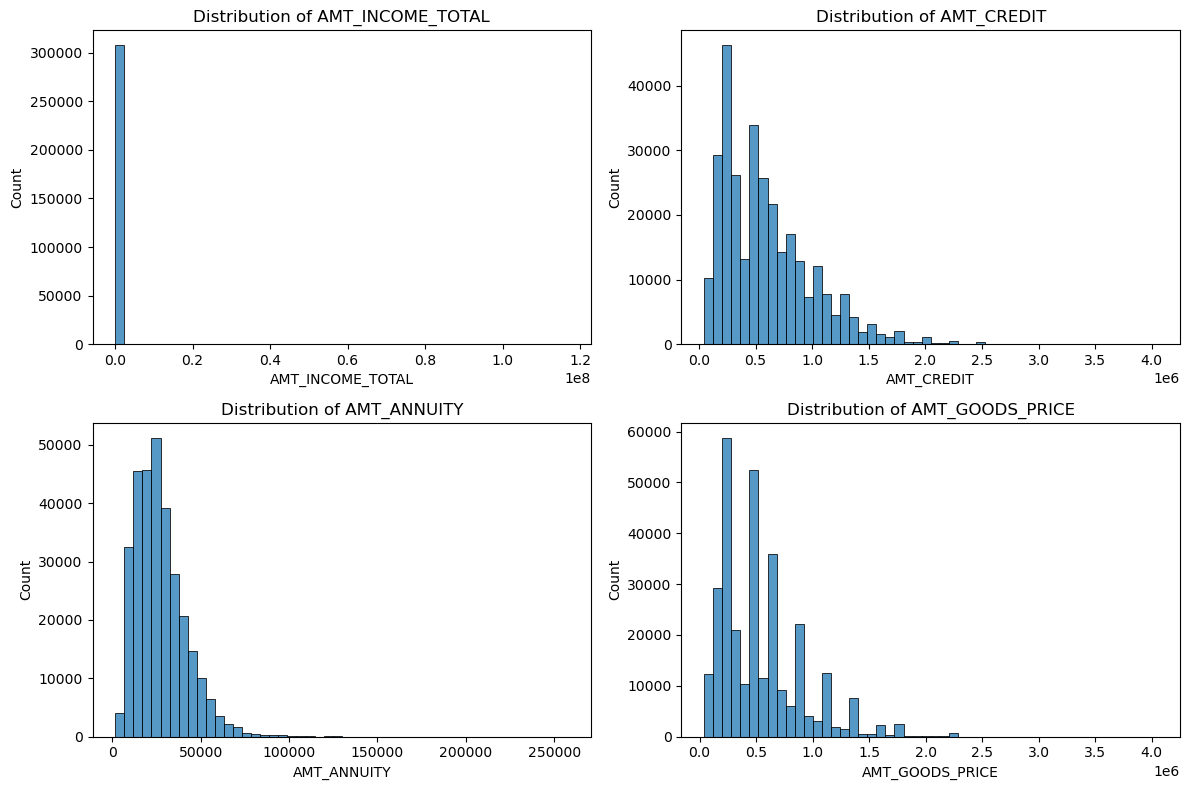

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for column, ax in zip(financial_columns, axes.flatten()):
    sns.histplot(
        data=df_train,
        x=column,
        bins=50,
        kde=False,
        ax=ax
    )
    ax.set_title(f"Distribution of {column}")

plt.tight_layout()
plt.show()

### Step 11 — Analyze outliers in financial variables
### Calculate the IQR and outlier counts

In [ ]:
financial_columns = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE"
]

outlier_results = []

for column in financial_columns:
    series = df_train[column].dropna()

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (series < lower_bound) |
        (series > upper_bound)
    )

    outlier_results.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": int(outliers.sum()),
        "Outlier_Percentage": outliers.mean() * 100
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df.round(2))

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,AMT_INCOME_TOTAL,112500.0,202500.0,90000.0,-22500.0,337500.0,14035,4.56
1,AMT_CREDIT,270000.0,808650.0,538650.0,-537975.0,1616625.0,6562,2.13
2,AMT_ANNUITY,16524.0,34596.0,18072.0,-10584.0,61704.0,7504,2.44
3,AMT_GOODS_PRICE,238500.0,679500.0,441000.0,-423000.0,1341000.0,14728,4.79


#### Compare the distributions by target

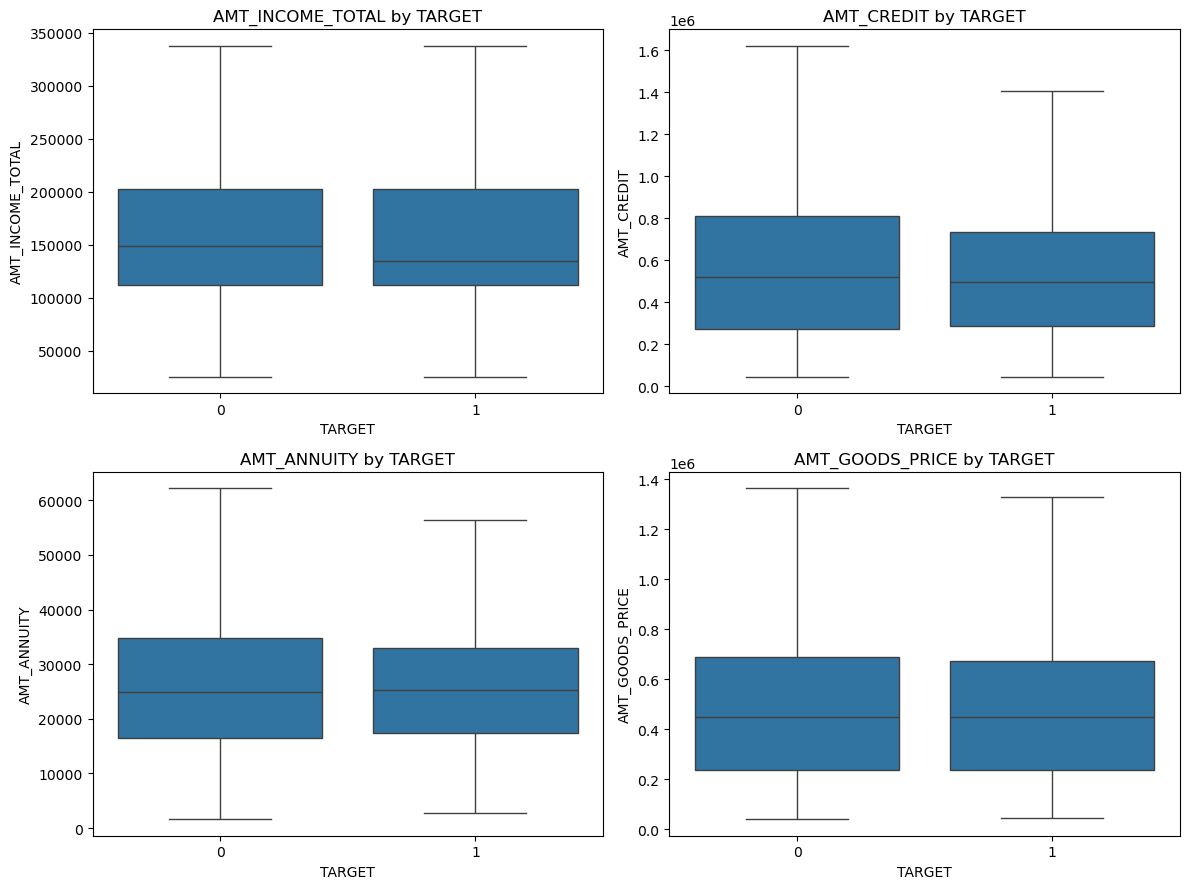

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for column, ax in zip(financial_columns, axes.flatten()):
    sns.boxplot(
        data=df_train,
        x="TARGET",
        y=column,
        ax=ax,
        showfliers=False
    )
    ax.set_title(f"{column} by TARGET")

plt.tight_layout()
plt.show()

#### Step 12 — Create financial risk features
### Create a separate feature-engineering dataset

In [ ]:
df_model = df_train.copy()

print("Original shape:", df_train.shape)
print("Model dataset shape:", df_model.shape)

Original shape: (307511, 122)
Model dataset shape: (307511, 122)


### Engineer three financial ratios

In [ ]:
# Credit amount relative to annual income
df_model["CREDIT_INCOME_RATIO"] = (
    df_model["AMT_CREDIT"] /
    df_model["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

# Annual loan annuity relative to annual income
df_model["ANNUITY_INCOME_RATIO"] = (
    (df_model["AMT_ANNUITY"] * 12) /
    df_model["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

# Loan amount relative to the price of the financed goods
df_model["CREDIT_GOODS_RATIO"] = (
    df_model["AMT_CREDIT"] /
    df_model["AMT_GOODS_PRICE"].replace(0, np.nan)
)

print("Financial risk features created.")

display(
    df_model[
        [
            "AMT_INCOME_TOTAL",
            "AMT_CREDIT",
            "AMT_ANNUITY",
            "AMT_GOODS_PRICE",
            "CREDIT_INCOME_RATIO",
            "ANNUITY_INCOME_RATIO",
            "CREDIT_GOODS_RATIO"
        ]
    ].head()
)

Financial risk features created.


,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,CREDIT_GOODS_RATIO
0,202500.0,406597.5,24700.5,351000.0,2.007889,1.463733,1.158397
1,270000.0,1293502.5,35698.5,1129500.0,4.790750,1.586600,1.145199
2,67500.0,135000.0,6750.0,135000.0,2.000000,1.200000,1.000000
3,135000.0,312682.5,29686.5,297000.0,2.316167,2.638800,1.052803
4,121500.0,513000.0,21865.5,513000.0,4.222222,2.159556,1.000000


### Compare the new features across target groups

In [ ]:
ratio_features = [
    "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO",
    "CREDIT_GOODS_RATIO"
]

display(
    df_model.groupby("TARGET")[ratio_features]
    .median()
    .T
)

TARGET,0,1
CREDIT_INCOME_RATIO,3.266653,3.253143
ANNUITY_INCOME_RATIO,1.947360,2.031529
CREDIT_GOODS_RATIO,1.118800,1.145200


### Step 13 — Identify categorical features
### Find categorical columns

In [ ]:
categorical_columns = df_model.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Number of categorical columns:", len(categorical_columns))
print("\nCategorical columns:")

for column in categorical_columns:
    print(column)

Number of categorical columns: 16

Categorical columns:
NAME_CONTRACT_TYPE
CODE_GENDER
FLAG_OWN_CAR
FLAG_OWN_REALTY
NAME_TYPE_SUITE
NAME_INCOME_TYPE
NAME_EDUCATION_TYPE
NAME_FAMILY_STATUS
NAME_HOUSING_TYPE
OCCUPATION_TYPE
WEEKDAY_APPR_PROCESS_START
ORGANIZATION_TYPE
FONDKAPREMONT_MODE
HOUSETYPE_MODE
WALLSMATERIAL_MODE
EMERGENCYSTATE_MODE


### Inspect the number of unique values

In [ ]:
category_summary = pd.DataFrame({
    "Unique_Values": df_model[categorical_columns].nunique(),
    "Missing_Count": df_model[categorical_columns].isna().sum()
}).sort_values("Unique_Values", ascending=False)

display(category_summary)

,Unique_Values,Missing_Count
ORGANIZATION_TYPE,58,0
OCCUPATION_TYPE,18,96391
NAME_INCOME_TYPE,8,0
NAME_TYPE_SUITE,7,1292
WALLSMATERIAL_MODE,7,156341
WEEKDAY_APPR_PROCESS_START,7,0
NAME_FAMILY_STATUS,6,0
NAME_HOUSING_TYPE,6,0
NAME_EDUCATION_TYPE,5,0
FONDKAPREMONT_MODE,4,210295


### Inspect the most common categories

In [ ]:
for column in categorical_columns[:5]:
    print(f"\n{column}")
    display(df_model[column].value_counts(dropna=False).head(10))


NAME_CONTRACT_TYPE


NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64


CODE_GENDER


CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64


FLAG_OWN_CAR


FLAG_OWN_CAR
N    202924
Y    104587
Name: count, dtype: int64


FLAG_OWN_REALTY


FLAG_OWN_REALTY
Y    213312
N     94199
Name: count, dtype: int64


NAME_TYPE_SUITE


NAME_TYPE_SUITE
Unaccompanied      248526
Family              40149
Spouse, partner     11370
Children             3267
Other_B              1770
NaN                  1292
Other_A               866
Group of people       271
Name: count, dtype: int64

### ep 14: Prepare the data for machine learning

### Separate features and target

In [ ]:
# Separate the target variable from the input features
X = df_model.drop(columns=["TARGET", "SK_ID_CURR"])
y = df_model["TARGET"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

Features shape: (307511, 123)
Target shape: (307511,)

Target distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Target percentages:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


### Split the data

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Validation features:", X_valid.shape)

print("\nTraining target distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nValidation target distribution (%):")
print((y_valid.value_counts(normalize=True) * 100).round(2))

Training features: (246008, 123)
Validation features: (61503, 123)

Training target distribution (%):
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64

Validation target distribution (%):
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


### Step 15: Create the preprocessing pipeline

### 15.1 — Import the required libraries

In [ ]:
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("Preprocessing libraries imported successfully.")

Preprocessing libraries imported successfully.


### 15.2 — Identify numerical and categorical columns

In [ ]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumerical feature examples:")
print(numeric_features[:10])

print("\nCategorical feature examples:")
print(categorical_features[:10])

Number of numerical features: 107
Number of categorical features: 16

Numerical feature examples:
['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH']

Categorical feature examples:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE']


### 16.1 — Create the numerical pipeline

In [ ]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

print("Numerical preprocessing pipeline created.")

Numerical preprocessing pipeline created.


### 16.2 — Create the categorical pipeline

In [ ]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

print("Categorical preprocessing pipeline created.")

Categorical preprocessing pipeline created.


### 16.3 — Combine both pipelines

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Combined preprocessing pipeline created.")

Combined preprocessing pipeline created.


### Step 17: Train the baseline Logistic Regression model

### 17.1 — Create the model pipeline

In [ ]:
from sklearn.linear_model import LogisticRegression

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            solver="liblinear",
            random_state=42
        ))
    ]
)

print("Baseline Logistic Regression pipeline created.")

Baseline Logistic Regression pipeline created.


### 17.2 — Train the model

In [ ]:
model.fit(X_train, y_train)

print("Baseline model training completed.")

Baseline model training completed.


### Step 18: Evaluate the baseline model

### 18.1 — Generate predictions

In [ ]:
# Predict the probability of payment difficulties
y_valid_proba = model.predict_proba(X_valid)[:, 1]

# Predict the class using the default threshold of 0.5
y_valid_pred = model.predict(X_valid)

print("Probability predictions generated:", len(y_valid_proba))
print("Class predictions generated:", len(y_valid_pred))

Probability predictions generated: 61503
Class predictions generated: 61503


### 18.2 — Calculate evaluation metrics

In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

roc_auc = roc_auc_score(y_valid, y_valid_proba)
avg_precision = average_precision_score(y_valid, y_valid_proba)
precision = precision_score(y_valid, y_valid_pred, zero_division=0)
recall = recall_score(y_valid, y_valid_pred, zero_division=0)
f1 = f1_score(y_valid, y_valid_pred, zero_division=0)

print("ROC-AUC:", round(roc_auc, 4))
print("Average Precision (PR-AUC summary):", round(avg_precision, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_valid, y_valid_pred))

print("\nClassification Report:")
print(classification_report(y_valid, y_valid_pred, zero_division=0))

ROC-AUC: 0.7493
Average Precision (PR-AUC summary): 0.2285
Precision: 0.1619
Recall: 0.6765
F1 Score: 0.2613

Confusion Matrix:
[[39151 17387]
 [ 1606  3359]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.69      0.80     56538
           1       0.16      0.68      0.26      4965

    accuracy                           0.69     61503
   macro avg       0.56      0.68      0.53     61503
weighted avg       0.90      0.69      0.76     61503



### Step 19: Visualize the model's performance

### 19.1 — Plot the confusion matrix

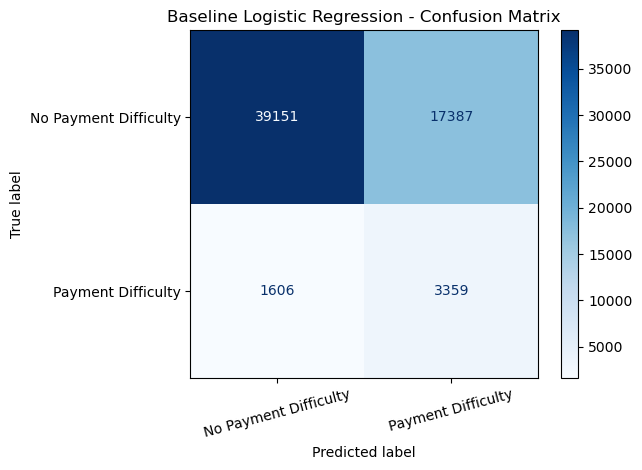

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    y_valid_pred,
    display_labels=["No Payment Difficulty", "Payment Difficulty"],
    cmap="Blues",
    values_format="d"
)

plt.title("Baseline Logistic Regression - Confusion Matrix")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 19.2 — Plot the ROC curve

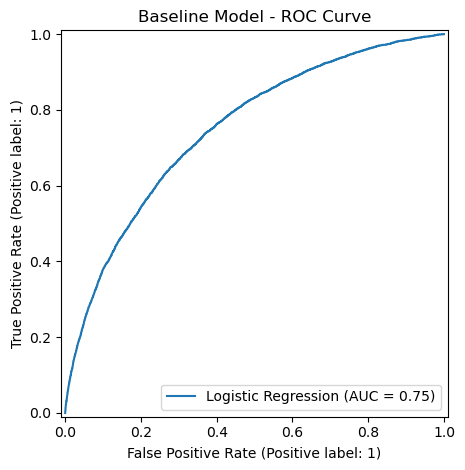

In [ ]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_valid,
    y_valid_proba,
    name="Logistic Regression"
)

plt.title("Baseline Model - ROC Curve")
plt.tight_layout()
plt.show()

### Step 20: Analyze the ROC-AUC and Precision–Recall performance

In [ ]:
### Baseline model evaluation summary
# Summarize the baseline model metrics
baseline_results = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "Average Precision",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Score": [
        roc_auc,
        avg_precision,
        precision,
        recall,
        f1
    ]
})

display(baseline_results.round(4))

,Metric,Score
0,ROC-AUC,0.7493
1,Average Precision,0.2285
2,Precision,0.1619
3,Recall,0.6765
4,F1 Score,0.2613


### Step 20.1 — Compare against a simple benchmark

In [ ]:
positive_rate = y_valid.mean()

print("Validation positive-class rate:", round(positive_rate, 4))
print("Baseline model ROC-AUC:", round(roc_auc, 4))
print("Baseline model Average Precision:", round(avg_precision, 4))

Validation positive-class rate: 0.0807
Baseline model ROC-AUC: 0.7493
Baseline model Average Precision: 0.2285


### Step 21: Analyze different risk thresholds
## 21.1 — Compare thresholds

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50]

threshold_results = []

for threshold in thresholds:
    predictions = (y_valid_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_valid, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_valid, predictions, zero_division=0
        ),
        "Flagged Applicants": int(predictions.sum())
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1 Score,Flagged Applicants
0,0.1,0.0822,0.9976,0.1519,60250
1,0.2,0.0914,0.9732,0.1671,52861
2,0.3,0.1085,0.9114,0.1938,41721
3,0.4,0.1324,0.8117,0.2277,30429
4,0.5,0.1619,0.6765,0.2613,20746


### Step 22: Visualize the threshold trade-off

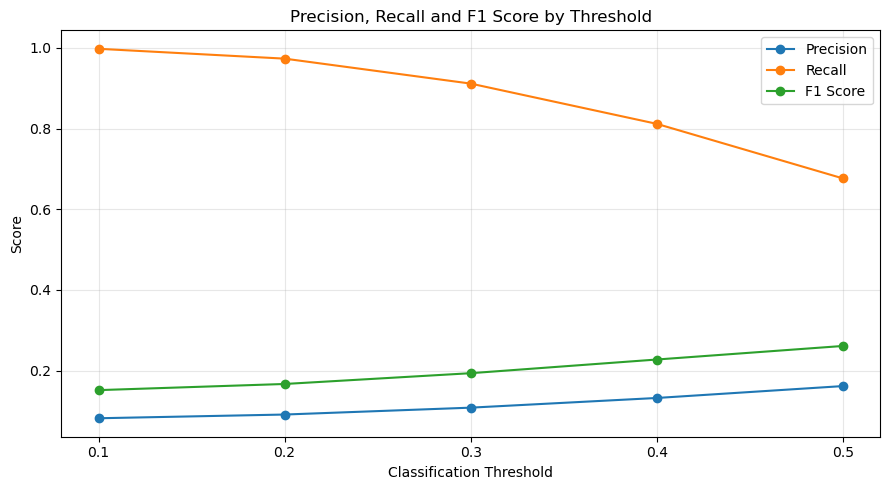

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 Score by Threshold")
plt.xticks(thresholds)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Step 23 — Identify the most influential features
23.1 Add a Markdown heading

In [ ]:
### Model Explainability — Feature Importance
# Retrieve the fitted preprocessing pipeline
fitted_preprocessor = model.named_steps["preprocessor"]

# Get the transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Retrieve Logistic Regression coefficients
coefficients = model.named_steps["classifier"].coef_[0]

# Create a feature importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Importance": np.abs(coefficients)
})

# Display the 20 most influential features by coefficient magnitude
top_features = feature_importance.sort_values(
    by="Absolute_Importance",
    ascending=False
).head(20)

display(top_features)

,Feature,Coefficient,Absolute_Importance
230,cat__ORGANIZATION_TYPE_XNA,-6.352279,6.352279
7,num__DAYS_EMPLOYED,6.085746,6.085746
126,cat__NAME_INCOME_TYPE_Pensioner,-4.432820,4.432820
130,cat__NAME_INCOME_TYPE_Working,2.320423,2.320423
124,cat__NAME_INCOME_TYPE_Commercial associate,2.263760,2.263760
127,cat__NAME_INCOME_TYPE_State servant,2.248516,2.248516
129,cat__NAME_INCOME_TYPE_Unemployed,-1.928959,1.928959
131,cat__NAME_EDUCATION_TYPE_Academic degree,-1.236302,1.236302
12,num__FLAG_EMP_PHONE,1.060353,1.060353
209,cat__ORGANIZATION_TYPE_Realtor,0.861809,0.861809


### Step 24: Visualize the top 20 features
### 24.1 Add a Markdown heading

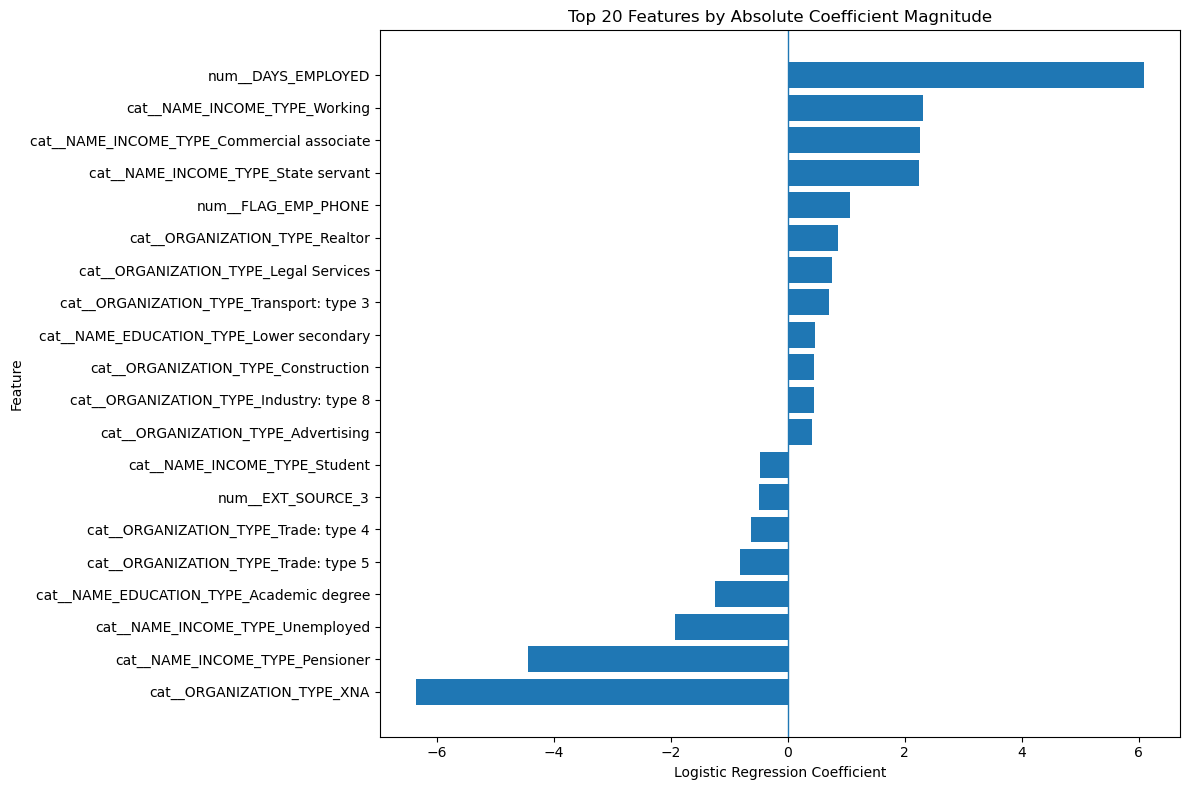

In [ ]:
### Top 20 Features Influencing Credit Risk Predictions
import matplotlib.pyplot as plt

# Sort features by absolute coefficient magnitude
top_features = feature_importance.nlargest(
    20, "Absolute_Importance"
).sort_values("Coefficient")

plt.figure(figsize=(12, 8))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, linewidth=1)
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 20 Features by Absolute Coefficient Magnitude")
plt.tight_layout()
plt.show()

### Step 26: Train a Random Forest model
26.1 — Add a Markdown heading

In [ ]:
### Model Comparison — Random Forest

### 26.2 — Create the Random Forest model

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=12,
            min_samples_leaf=50,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Random Forest pipeline created.")

Random Forest pipeline created.


### 26.3 — Train the model
### Train Random Forest

In [ ]:
rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


### Step 27: Evaluate the Random Forest model
27.1 — Generate predictions

In [ ]:
### Random Forest Model Evaluation
# Predict probabilities on the validation dataset
rf_valid_proba = rf_model.predict_proba(X_valid)[:, 1]

# Predict classes using the default threshold of 0.5
rf_valid_pred = rf_model.predict(X_valid)

print("Random Forest predictions generated.")
print("Validation predictions:", len(rf_valid_pred))

Random Forest predictions generated.
Validation predictions: 61503


### 27.2 — Calculate evaluation metrics

In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

rf_roc_auc = roc_auc_score(y_valid, rf_valid_proba)
rf_avg_precision = average_precision_score(y_valid, rf_valid_proba)
rf_precision = precision_score(y_valid, rf_valid_pred, zero_division=0)
rf_recall = recall_score(y_valid, rf_valid_pred, zero_division=0)
rf_f1 = f1_score(y_valid, rf_valid_pred, zero_division=0)

print("Random Forest ROC-AUC:", round(rf_roc_auc, 4))
print("Random Forest Average Precision:", round(rf_avg_precision, 4))
print("Random Forest Precision:", round(rf_precision, 4))
print("Random Forest Recall:", round(rf_recall, 4))
print("Random Forest F1 Score:", round(rf_f1, 4))

Random Forest ROC-AUC: 0.7379
Random Forest Average Precision: 0.2165
Random Forest Precision: 0.1708
Random Forest Recall: 0.601
Random Forest F1 Score: 0.266


### Step 28: Compare both models

In [ ]:
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "ROC_AUC": [roc_auc, rf_roc_auc],
    "Average_Precision": [avg_precision, rf_avg_precision],
    "Precision": [precision, rf_precision],
    "Recall": [recall, rf_recall],
    "F1_Score": [f1, rf_f1]
})

display(model_comparison.round(4))

,Model,ROC_AUC,Average_Precision,Precision,Recall,F1_Score
0,Logistic Regression,0.7493,0.2285,0.1619,0.6765,0.2613
1,Random Forest,0.7379,0.2165,0.1708,0.6010,0.2660


### Step 29: Compare ROC curves for both models

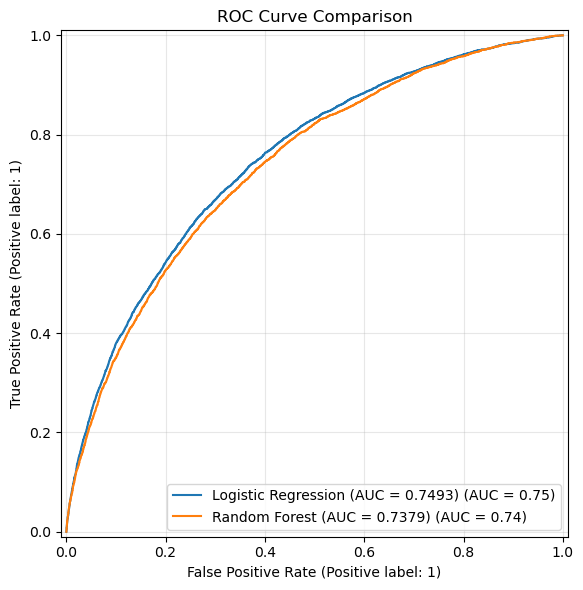

In [ ]:
### ROC Curve Comparison — Logistic Regression vs Random Forest
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))

RocCurveDisplay.from_predictions(
    y_valid,
    y_valid_proba,
    name=f"Logistic Regression (AUC = {roc_auc:.4f})",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_valid,
    rf_valid_proba,
    name=f"Random Forest (AUC = {rf_roc_auc:.4f})",
    ax=ax
)

ax.set_title("ROC Curve Comparison")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Step 30: Compare Precision–Recall curves

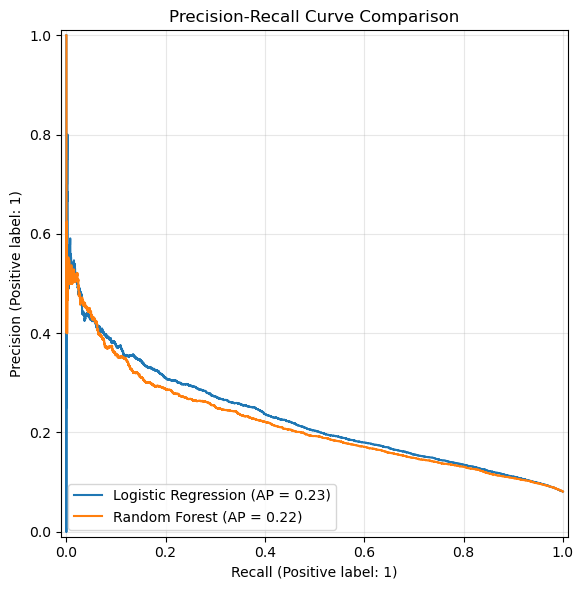

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))

PrecisionRecallDisplay.from_predictions(
    y_valid,
    y_valid_proba,
    name="Logistic Regression",
    ax=ax
)

PrecisionRecallDisplay.from_predictions(
    y_valid,
    rf_valid_proba,
    name="Random Forest",
    ax=ax
)

ax.set_title("Precision-Recall Curve Comparison")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Step 31: Compare Precision–Recall performance numerically

In [ ]:
### Precision-Recall Performance Comparison
from sklearn.metrics import average_precision_score

# Calculate Average Precision for both models
lr_ap = average_precision_score(y_valid, y_valid_proba)
rf_ap = average_precision_score(y_valid, rf_valid_proba)

# Calculate the positive-class baseline
positive_class_rate = y_valid.mean()

pr_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Average_Precision": [lr_ap, rf_ap],
    "Positive_Class_Baseline": [
        positive_class_rate,
        positive_class_rate
    ]
})

display(pr_comparison.round(4))

,Model,Average_Precision,Positive_Class_Baseline
0,Logistic Regression,0.2285,0.0807
1,Random Forest,0.2165,0.0807


### Step 32: Tune Logistic Regression
### Hyperparameter Tuning — Logistic Regression

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Test different regularization strengths
param_grid = {
    "classifier__C": [0.01, 0.1, 1.0, 10.0]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=2,
    refit=True
)

print("Hyperparameter tuning setup completed.")

Hyperparameter tuning setup completed.


### Step 32.1 — Run the tuning

In [ ]:
### Memory-Safe Logistic Regression Tuning
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "classifier__C": [0.01, 0.1, 1.0]
}

cv = StratifiedKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    verbose=2,
    refit=True,
    error_score="raise"
)

print("Memory-safe tuning setup completed.")

Memory-safe tuning setup completed.


In [ ]:
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print(
    "Best cross-validation Average Precision:",
    round(grid_search.best_score_, 4)
)

Fitting 2 folds for each of 3 candidates, totalling 6 fits
[CV] END .................................classifier__C=0.01; total time=  15.7s
[CV] END .................................classifier__C=0.01; total time=  12.7s
[CV] END ..................................classifier__C=0.1; total time=  28.6s
[CV] END ..................................classifier__C=0.1; total time=  23.7s
[CV] END ..................................classifier__C=1.0; total time=  47.4s
[CV] END ..................................classifier__C=1.0; total time=  48.3s
Best parameters: {'classifier__C': 1.0}
Best cross-validation Average Precision: 0.2176


### Step 33: Evaluate the tuned Logistic Regression model
### Tuned Logistic Regression — Validation Evaluation

In [ ]:
# Get the best model selected by cross-validation
best_model = grid_search.best_estimator_

# Predict probabilities on the untouched validation set
tuned_valid_proba = best_model.predict_proba(X_valid)[:, 1]

# Evaluate ranking performance
tuned_roc_auc = roc_auc_score(y_valid, tuned_valid_proba)
tuned_avg_precision = average_precision_score(
    y_valid, tuned_valid_proba
)

print("Best parameters:", grid_search.best_params_)
print("Tuned ROC-AUC:", round(tuned_roc_auc, 4))
print("Tuned Average Precision:", round(tuned_avg_precision, 4))

print("\nOriginal Logistic Regression:")
print("ROC-AUC:", round(roc_auc, 4))
print("Average Precision:", round(avg_precision, 4))

Best parameters: {'classifier__C': 1.0}
Tuned ROC-AUC: 0.7493
Tuned Average Precision: 0.2285

Original Logistic Regression:
ROC-AUC: 0.7493
Average Precision: 0.2285


### Step 34: Compare all three model results
### Final Model Performance Comparison

In [ ]:
final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression (Baseline)",
        "Random Forest",
        "Logistic Regression (Tuned)"
    ],
    "ROC_AUC": [
        roc_auc,
        rf_roc_auc,
        tuned_roc_auc
    ],
    "Average_Precision": [
        avg_precision,
        rf_avg_precision,
        tuned_avg_precision
    ]
})

display(final_comparison.round(4))

,Model,ROC_AUC,Average_Precision
0,Logistic Regression (Baseline),0.7493,0.2285
1,Random Forest,0.7379,0.2165
2,Logistic Regression (Tuned),0.7493,0.2285


### Step 35: Check probability calibration
### Probability Calibration Analysis

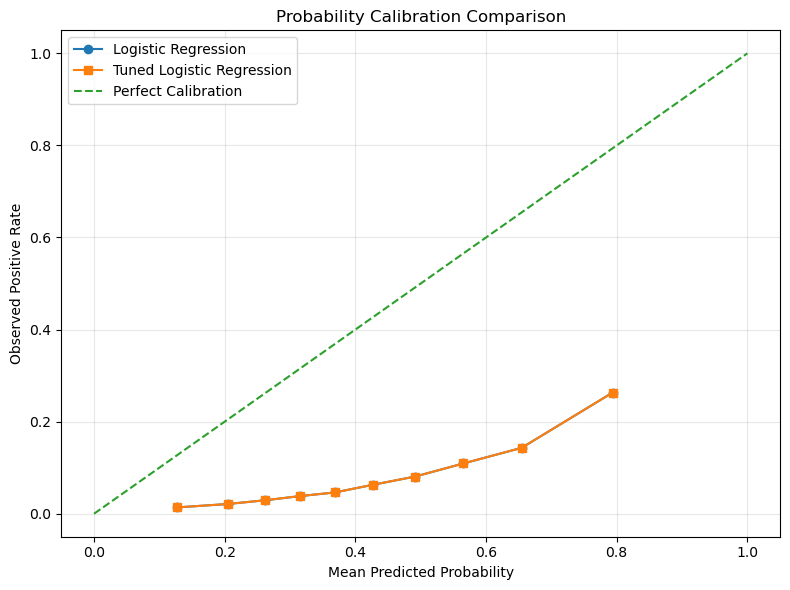

In [ ]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Compare predicted probabilities with observed positive rates
lr_fraction_positive, lr_mean_predicted = calibration_curve(
    y_valid,
    y_valid_proba,
    n_bins=10,
    strategy="quantile"
)

tuned_fraction_positive, tuned_mean_predicted = calibration_curve(
    y_valid,
    tuned_valid_proba,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(8, 6))

plt.plot(
    lr_mean_predicted,
    lr_fraction_positive,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    tuned_mean_predicted,
    tuned_fraction_positive,
    marker="s",
    label="Tuned Logistic Regression"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Positive Rate")
plt.title("Probability Calibration Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Step 36: Generate a model-validation summary
### Credit Risk Model Validation Summary

In [ ]:
validation_summary = pd.DataFrame({
    "Validation_Metric": [
        "ROC-AUC",
        "Average Precision",
        "Precision at 0.50 threshold",
        "Recall at 0.50 threshold",
        "F1 Score at 0.50 threshold"
    ],
    "Logistic_Regression": [
        roc_auc,
        avg_precision,
        precision,
        recall,
        f1
    ],
    "Random_Forest": [
        rf_roc_auc,
        rf_avg_precision,
        rf_precision,
        rf_recall,
        rf_f1
    ]
})

display(validation_summary.round(4))

The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.


,Validation_Metric,Logistic_Regression,Random_Forest
0,ROC-AUC,0.7493,0.7379
1,Average Precision,0.2285,0.2165
2,Precision at 0.50 threshold,0.1619,0.1708
3,Recall at 0.50 threshold,0.6765,0.6010
4,F1 Score at 0.50 threshold,0.2613,0.2660


### Step 37: Record the model-validation conclusion

#### Step 38 — Install and import SHAP

### 38.1 Add a Markdown heading
### SHAP — Model Explainability

### 38.2 Install SHAP

In [ ]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\shash\anaconda3\python.exe -m pip install --upgrade pip


#### 38.3 Import SHAP

In [ ]:
import shap

print("SHAP version:", shap.__version__)
print("SHAP imported successfully.")

SHAP version: 0.52.0
SHAP imported successfully.


### Step 39 — Prepare a small sample for explanation
### Prepare Validation Sample for SHAP

In [ ]:
# Select a reproducible sample from the validation set
X_shap = X_valid.sample(
    n=min(200, len(X_valid)),
    random_state=42
)

print("SHAP sample shape:", X_shap.shape)

SHAP sample shape: (200, 123)


### Step 40: Prepare the model for SHAP
### Explain Logistic Regression Predictions with SHAP

### 40.1 — Transform the sample

In [ ]:
# Use the fitted preprocessing pipeline
fitted_preprocessor = model.named_steps["preprocessor"]

# Transform the sampled applicants
X_shap_transformed = fitted_preprocessor.transform(X_shap)

# Retrieve the transformed feature names
shap_feature_names = fitted_preprocessor.get_feature_names_out()

print("Transformed sample shape:", X_shap_transformed.shape)
print("Number of feature names:", len(shap_feature_names))

Transformed sample shape: (200, 247)
Number of feature names: 247


#### 40.2 — Create the SHAP explainer

In [ ]:
# Explain the fitted Logistic Regression classifier
classifier = model.named_steps["classifier"]

explainer = shap.LinearExplainer(
    classifier,
    X_shap_transformed
)

print("SHAP LinearExplainer created successfully.")

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


SHAP LinearExplainer created successfully.


### 40.3 — Calculate SHAP values

In [ ]:
shap_values = explainer(
    X_shap_transformed
)

print("SHAP values calculated successfully.")
print("SHAP values shape:", shap_values.values.shape)

SHAP values calculated successfully.
SHAP values shape: (200, 247)


### Step 41: Visualize global feature importance

In [ ]:
### SHAP Global Feature Importance
# Global importance: mean absolute SHAP value per feature
shap_importance = pd.DataFrame({
    "Feature": shap_feature_names,
    "Mean_Absolute_SHAP": np.abs(shap_values.values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

display(shap_importance.head(20).round(4))

,Feature,Mean_Absolute_SHAP
7,num__DAYS_EMPLOYED,5.2143
230,cat__ORGANIZATION_TYPE_XNA,2.0912
126,cat__NAME_INCOME_TYPE_Pensioner,1.4593
130,cat__NAME_INCOME_TYPE_Working,1.1609
12,num__FLAG_EMP_PHONE,0.9096
124,cat__NAME_INCOME_TYPE_Commercial associate,0.7319
29,num__EXT_SOURCE_3,0.3686
127,cat__NAME_INCOME_TYPE_State servant,0.3314
28,num__EXT_SOURCE_2,0.3016
4,num__AMT_GOODS_PRICE,0.2547


### Step 42: Plot the top 20 features

In [ ]:
### SHAP Global Importance Visualization

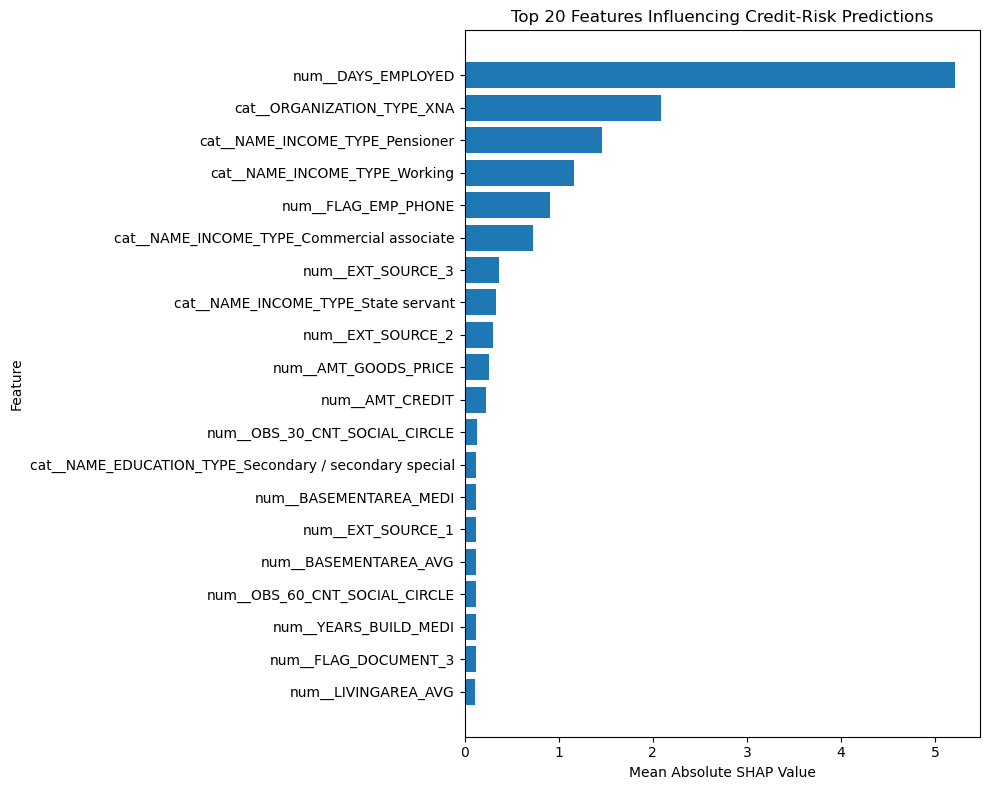

In [ ]:
top_shap = shap_importance.head(20).sort_values(
    "Mean_Absolute_SHAP",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_shap["Feature"],
    top_shap["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top 20 Features Influencing Credit-Risk Predictions")
plt.tight_layout()
plt.show()

### Step 43: Explain an individual applicant's prediction

In [ ]:
### Individual Applicant Risk Explanation

### 43.1 — Select one applicant

In [ ]:
# Select the first applicant from the SHAP sample
applicant_index = 0

applicant_shap = shap_values[applicant_index]

print("Applicant's actual TARGET:", y_valid.loc[X_shap.index[applicant_index]])
print(
    "Predicted payment-difficulty probability:",
    round(float(y_valid_proba[X_valid.index.get_loc(
        X_shap.index[applicant_index]
    )]), 4)
)

Applicant's actual TARGET: 0
Predicted payment-difficulty probability: 0.6261


### 43.2 — Plot the individual SHAP explanation

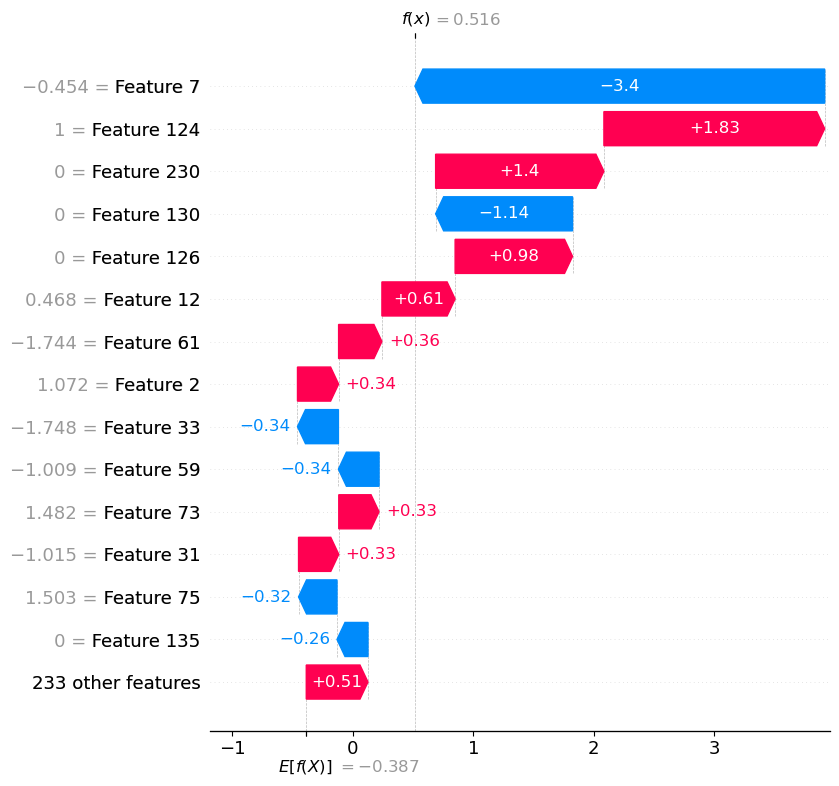

In [ ]:
shap.plots.waterfall(
    applicant_shap,
    max_display=15
)

### Step 44: Improve the SHAP feature labels
### Improve SHAP Explanation Labels

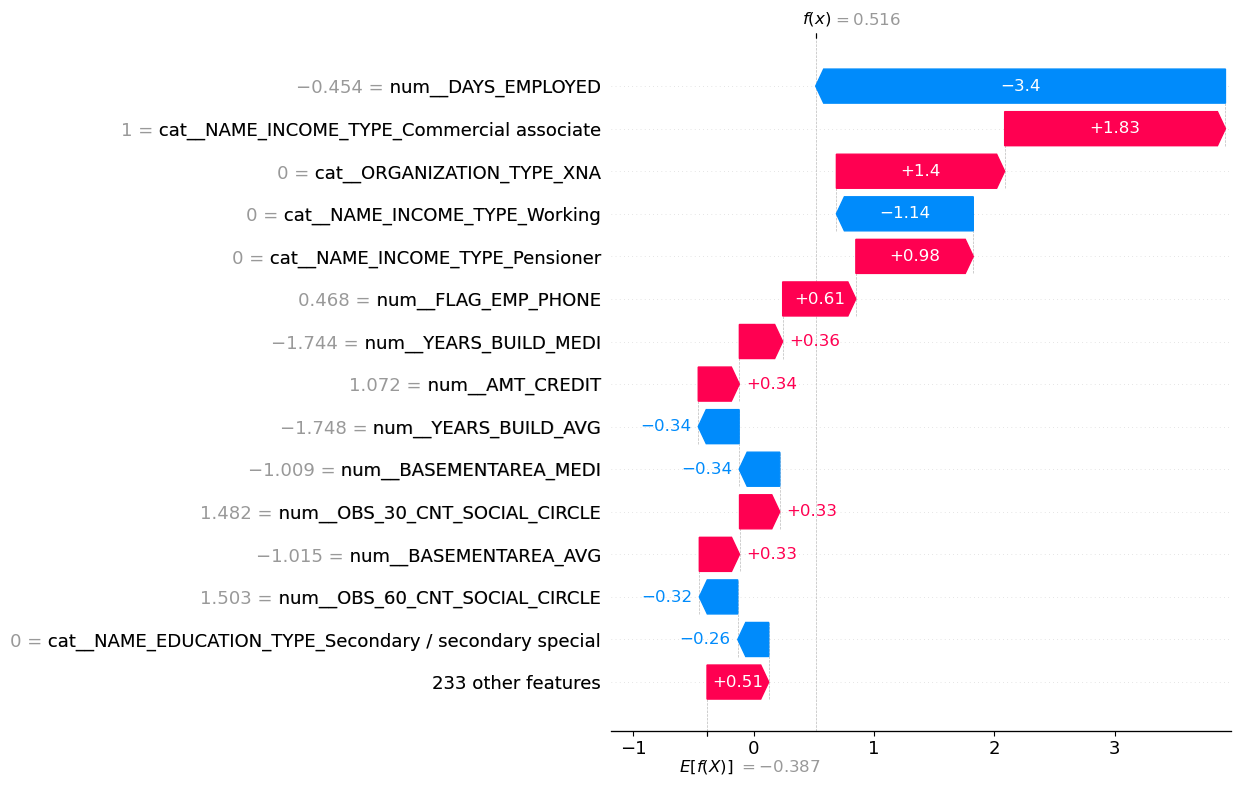

In [ ]:
# Attach the real transformed feature names to the SHAP explanation
applicant_shap_named = shap.Explanation(
    values=shap_values.values[applicant_index],
    base_values=shap_values.base_values[applicant_index],
    data=X_shap_transformed[applicant_index].toarray().ravel()
        if hasattr(X_shap_transformed[applicant_index], "toarray")
        else X_shap_transformed[applicant_index],
    feature_names=shap_feature_names
)

# Display the explanation with meaningful feature names
shap.plots.waterfall(
    applicant_shap_named,
    max_display=15
)

#### Step 45: Save your trained model

In [ ]:
### Save the Best Credit Risk Model

In [ ]:
import joblib
import json
from pathlib import Path

# Use the project folder that contains your datasets folder
PROJECT_PATH = DATA_PATH.parent

MODEL_PATH = PROJECT_PATH / "models"
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# Save the tuned Logistic Regression pipeline
model_file = MODEL_PATH / "credence_risk_model.joblib"
joblib.dump(best_model, model_file)

# Save the model's evaluation results
metrics = {
    "model": "Tuned Logistic Regression",
    "best_parameters": grid_search.best_params_,
    "roc_auc": float(tuned_roc_auc),
    "average_precision": float(tuned_avg_precision),
    "validation_rows": int(len(y_valid)),
    "random_state": 42
}

metrics_file = MODEL_PATH / "model_metrics.json"

with open(metrics_file, "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4)

print("Model saved:", model_file)
print("Metrics saved:", metrics_file)
print("Model file exists:", model_file.exists())
print("Metrics file exists:", metrics_file.exists())

Model saved: D:\Credence Risk — Credit Risk Intelligence & Validation Platform\models\credence_risk_model.joblib
Metrics saved: D:\Credence Risk — Credit Risk Intelligence & Validation Platform\models\model_metrics.json
Model file exists: True
Metrics file exists: True


### Step 46: Verify that the saved model works

In [ ]:
### Verify Saved Model

In [ ]:
# Load the saved model
loaded_model = joblib.load(model_file)

# Generate predictions for a few validation applicants
sample_applicants = X_valid.head(5)

sample_probabilities = loaded_model.predict_proba(
    sample_applicants
)[:, 1]

print("Saved model loaded successfully.")
print("\nPredicted payment-difficulty probabilities:")

for i, probability in enumerate(sample_probabilities, start=1):
    print(f"Applicant {i}: {probability:.4f}")

Saved model loaded successfully.

Predicted payment-difficulty probabilities:
Applicant 1: 0.3633
Applicant 2: 0.3278
Applicant 3: 0.7863
Applicant 4: 0.5548
Applicant 5: 0.5698


### Step 47: Create a credit-risk scoring function

### 47.1 — Add a Markdown heading
### Build a Reusable Credit Risk Scoring Function

### 47.2 — Run this Python cell

In [ ]:
def score_applicants(applicant_data, fitted_model=loaded_model):
    """
    Generate payment-difficulty probabilities for applicant records.

    applicant_data:
        DataFrame containing the expected model input columns.

    Returns:
        DataFrame with predicted probabilities and risk bands.
    """
    # Generate probabilities
    probabilities = fitted_model.predict_proba(applicant_data)[:, 1]

    # Create results
    results = applicant_data.copy()
    results["Predicted_Probability"] = probabilities

    # Illustrative risk bands, not approved lending thresholds
    results["Risk_Band"] = pd.cut(
        probabilities,
        bins=[-np.inf, 0.10, 0.30, 0.50, np.inf],
        labels=["Low", "Moderate", "Elevated", "High"],
        right=False
    )

    return results


print("Credit-risk scoring function created.")

Credit-risk scoring function created.


### Step 48: Test the scoring function

In [ ]:
### Test Credit Risk Scoring

In [ ]:
# Score five applicants from the validation dataset
scoring_results = score_applicants(X_valid.head(5))

display(
    scoring_results[
        ["Predicted_Probability", "Risk_Band"]
    ].round(4)
)

,Predicted_Probability,Risk_Band
256571,0.3633,Elevated
191493,0.3278,Elevated
103497,0.7863,High
130646,0.5548,High
211898,0.5698,High


In [1]:
import sys
print(sys.executable)
%pip install scikit-learn seaborn joblib

c:\python314\python.exe
Defaulting to user installation because normal site-packages is not writeable
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   --------------- ------------------------ 3.1/8.4 MB 20.5 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 24.2 MB/s  0:00:00
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)

   ---------- ----------------------------- 1/4 [joblib]
   ---------- ----------------------------- 1/4 [joblib]
   ---------- ----------------------------- 1/4 [joblib]
   ---------- ----------------------------- 1/4 [joblib]
   ---------- ----------------------------- 1/4 [joblib]
   ---------- --------------------

In [2]:
import sys, sklearn, pandas, joblib
print(sys.executable)
print(sklearn.__version__, pandas.__version__, joblib.__version__)

c:\python314\python.exe
1.9.1 3.0.5 1.6.0


In [3]:
import sys
print(sys.executable)
%pip install scikit-learn seaborn joblib

c:\python314\python.exe
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


### Step 7: Create the missing feature_columns.json

In [4]:
import joblib, json
from pathlib import Path

model = joblib.load("models/credence_risk_model.joblib")
cols = list(model.feature_names_in_)

Path("models/feature_columns.json").write_text(json.dumps(cols, indent=2))

print("Model type:", type(model).__name__)
print("Pipeline steps:", [name for name, _ in model.steps])
print("Number of features:", len(cols))
print("First 10 features:", cols[:10])
print(Path("models/model_metrics.json").read_text())

C:\Users\shash\AppData\Roaming\Python\Python314\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\shash\AppData\Roaming\Python\Python314\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\shash\AppData\Roaming\Python\Python314\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.6.1 whe

AttributeError: module 'sklearn.compose._column_transformer' has no attribute '_RemainderColsList'

### Step 8: Find the scikit-learn version that saved your model

In [5]:
import warnings, joblib

with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    try:
        joblib.load("models/credence_risk_model.joblib")
    except Exception:
        pass

print(str(w[0].message) if w else "No warning captured")

Trying to unpickle estimator SimpleImputer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
